# Descripción del dataset: CelebA (2026-11-02)

Este notebook describe **con qué datos se hicieron los experimentos de `celeba_regions` y `celeba_attractive`**: qué es CelebA, qué ve exactamente el modelo, cómo están distribuidos los atributos, y qué sesgos y límites tiene. Todas las figuras están pensadas para pasar **tal cual a una diapositiva** (16:9, letra grande, títulos que dicen la conclusión). Se guardan en `experimentation/experiments/02112026_celeba_dataset/`.

**Qué viene de dónde (para no mezclar):**
- *Calculado aquí* a partir de los archivos del proyecto: tamaños de las particiones, prevalencia de atributos, géneros, correlaciones, posiciones de landmarks, imágenes promedio.
- *Dato de la publicación original* (Liu et al., 2015), **no calculado aquí**: 10 177 identidades, 202 599 imágenes, 40 atributos binarios, 5 landmarks. El número de identidades no se puede verificar con los archivos que tenemos.

**Resolución que usa el modelo:** la imagen original alineada mide **178×218 px**. Se recorta al centro a **178×178** y se reduce a **64×64**; el ViT la parte en **parches de 4×4 px = rejilla de 16×16 = 256 parches**. (Los modelos de AwA2, en cambio, usan 32×32 con 64 parches.)

## 0. Configuración

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from matplotlib.patches import Rectangle

project_root = Path.cwd().resolve().parents[1]
sys.path.append(str(project_root))
from modules.figures import save_fig

ROOT = project_root / "data" / "celeba"
CACHE = ROOT / "celeba_test64.npz"                      # imágenes de test ya a 64×64 (la crea celeba_regions.ipynb)
OUTPUT_DIR = project_root / "experimentation" / "experiments" / "02112026_celeba_dataset"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Estilo "diapositiva": letra grande y fondo limpio
plt.rcParams.update({"font.size": 13, "axes.titlesize": 16, "axes.labelsize": 13, "figure.dpi": 100,
                     "axes.spines.top": False, "axes.spines.right": False})
FIG = (13, 7.3)                                          # proporción 16:9
IMG, RAW_W, RAW_H, PATCH, GRID = 64, 178, 218, 4, 16
print("raíz:", project_root)

raíz: /home/claude/work/interpretable-transformers


## 1. Los datos en bruto

Se leen tres archivos de CelebA: los **40 atributos** por imagen (`list_attr_celeba.csv`, valores −1/+1 que paso a 0/1), la **partición oficial** (`list_eval_partition.csv`: 0 = entrenamiento, 1 = validación, 2 = test) y los **5 landmarks alineados** (`list_landmarks_align_celeba.csv`).

In [2]:
A = pd.read_csv(ROOT / "list_attr_celeba.csv", index_col="image_id")
ATTR_NAMES = list(A.columns)
A = (A + 1) // 2                                          # -1/+1  ->  0/1
P = pd.read_csv(ROOT / "list_eval_partition.csv", index_col="image_id")["partition"].reindex(A.index)
L = pd.read_csv(ROOT / "list_landmarks_align_celeba.csv", index_col="image_id").reindex(A.index)
split = P.map({0: "entrenamiento", 1: "validación", 2: "test"})
print(f"{len(A):,} imágenes | {A.shape[1]} atributos | particiones: " + ", ".join(f"{k} {v:,}" for k, v in split.value_counts().items()))

202,599 imágenes | 40 atributos | particiones: entrenamiento 162,770, test 19,962, validación 19,867


guardado: experimentation/experiments/02112026_celeba_dataset/01_partitions_celeba.png


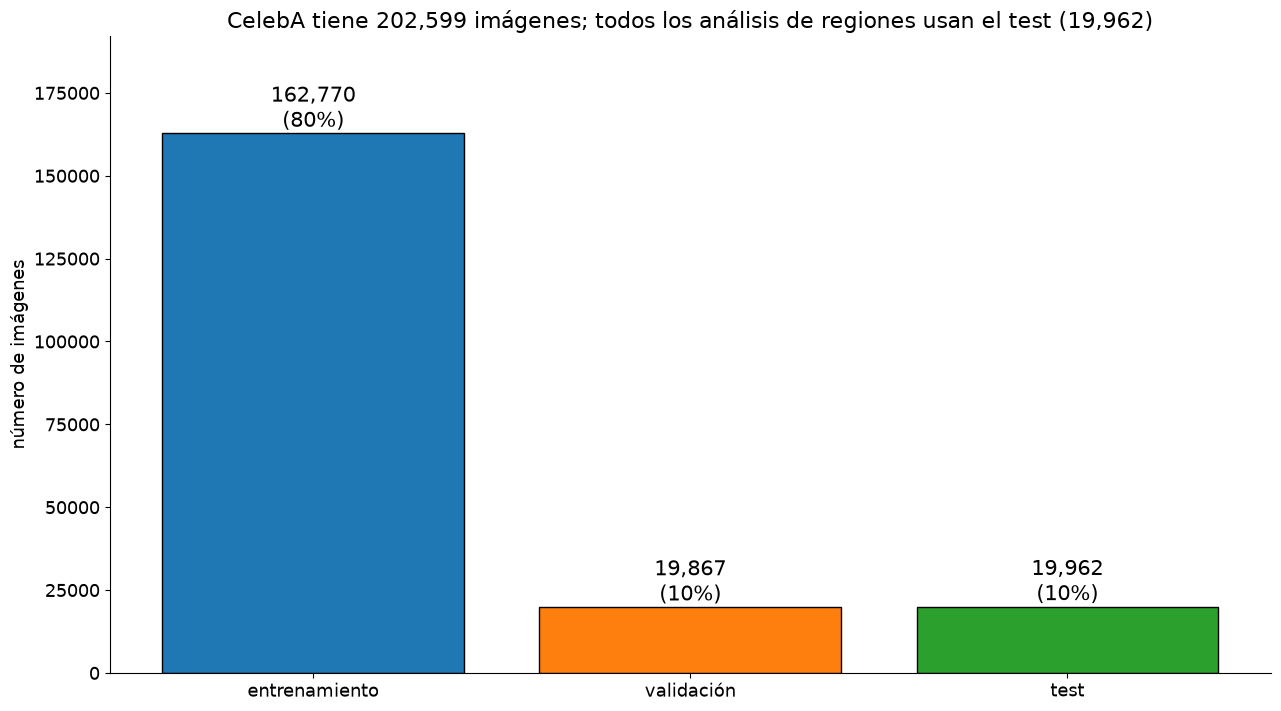

In [3]:
# FIGURA 1: tamaño de cada partición
cuenta = split.value_counts().reindex(["entrenamiento", "validación", "test"])
fig, ax = plt.subplots(figsize=FIG)
barras = ax.bar(cuenta.index, cuenta.values, color=["tab:blue", "tab:orange", "tab:green"], edgecolor="k")
for b, v in zip(barras, cuenta.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 2000, f"{v:,}\n({v / cuenta.sum():.0%})", ha="center", fontsize=15)
ax.set_ylabel("número de imágenes"); ax.set_ylim(0, cuenta.max() * 1.18)
ax.set_title(f"CelebA tiene {len(A):,} imágenes; todos los análisis de regiones usan el test ({cuenta['test']:,})")
plt.tight_layout(); save_fig(fig, "01_partitions", OUTPUT_DIR, tag="celeba", project_root=project_root); plt.show()

## 2. Qué ve exactamente el modelo (de la foto a los 256 parches)

Cuatro paneles con **la misma foto** en cada paso:
1. la imagen original alineada (178×218) y el recorte central que se le hace;
2. el recorte (178×178);
3. la imagen reducida a **64×64**, que es lo único que ve el modelo (ampliada aquí para que se vea el pixelado);
4. esa misma imagen con la **rejilla de 16×16 parches de 4×4 px** y los 5 landmarks.

**Lo importante para interpretar los resultados:** cada parche es muy pequeño. Un ojo ocupa 1–2 parches de ancho; la boca, unos 3–4. Por eso las "regiones" de ojos, nariz y boca son de pocos parches.

guardado: experimentation/experiments/02112026_celeba_dataset/02_from_photo_to_patches_celeba.png


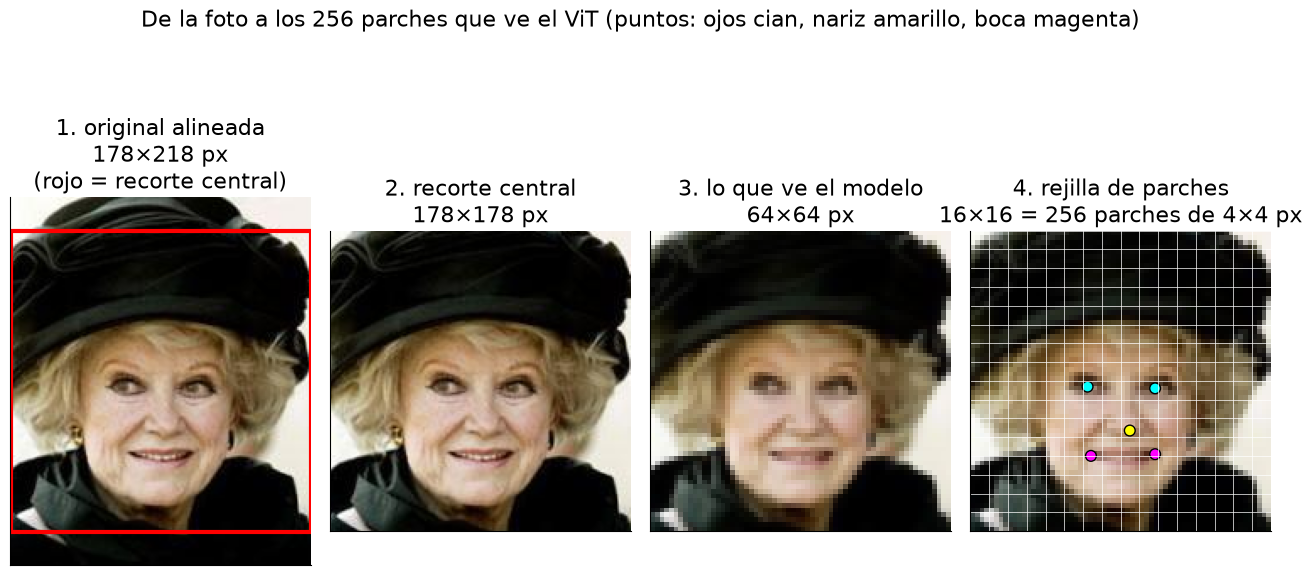

In [4]:
D = np.load(CACHE, allow_pickle=True)
X8, ATTR_T, LM, IDS = D["x"], D["attr"], D["lm"], list(D["ids"])          # test: 19 962 imágenes a 64×64
ATTR_T_NAMES = list(D["attr_names"]); N = len(X8)
i0 = 0
raw = Image.open(ROOT / "img_align_celeba" / "img_align_celeba" / IDS[i0]).convert("RGB")
crop = raw.crop((0, 20, RAW_W, 20 + RAW_W))

fig, axes = plt.subplots(1, 4, figsize=FIG)
axes[0].imshow(raw); axes[0].add_patch(Rectangle((0, 20), RAW_W, RAW_W, fill=False, ec="red", lw=3))
axes[0].set_title(f"1. original alineada\n{RAW_W}×{RAW_H} px\n(rojo = recorte central)")
axes[1].imshow(crop); axes[1].set_title(f"2. recorte central\n{RAW_W}×{RAW_W} px")
axes[2].imshow(X8[i0], interpolation="nearest"); axes[2].set_title(f"3. lo que ve el modelo\n{IMG}×{IMG} px")
axes[3].imshow(X8[i0], interpolation="nearest")
for k in range(0, IMG + 1, PATCH):
    axes[3].axhline(k - 0.5, color="w", lw=0.5); axes[3].axvline(k - 0.5, color="w", lw=0.5)
axes[3].scatter(LM[i0, :, 0], LM[i0, :, 1], c=["cyan", "cyan", "yellow", "magenta", "magenta"], s=60, edgecolors="k")
axes[3].set_title(f"4. rejilla de parches\n{GRID}×{GRID} = {GRID * GRID} parches de {PATCH}×{PATCH} px")
for ax in axes: ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("De la foto a los 256 parches que ve el ViT (puntos: ojos cian, nariz amarillo, boca magenta)", fontsize=16)
plt.tight_layout(); save_fig(fig, "02_from_photo_to_patches", OUTPUT_DIR, tag="celeba", project_root=project_root); plt.show()

## 3. Cómo son las caras: una muestra

guardado: experimentation/experiments/02112026_celeba_dataset/03_random_faces_celeba.png


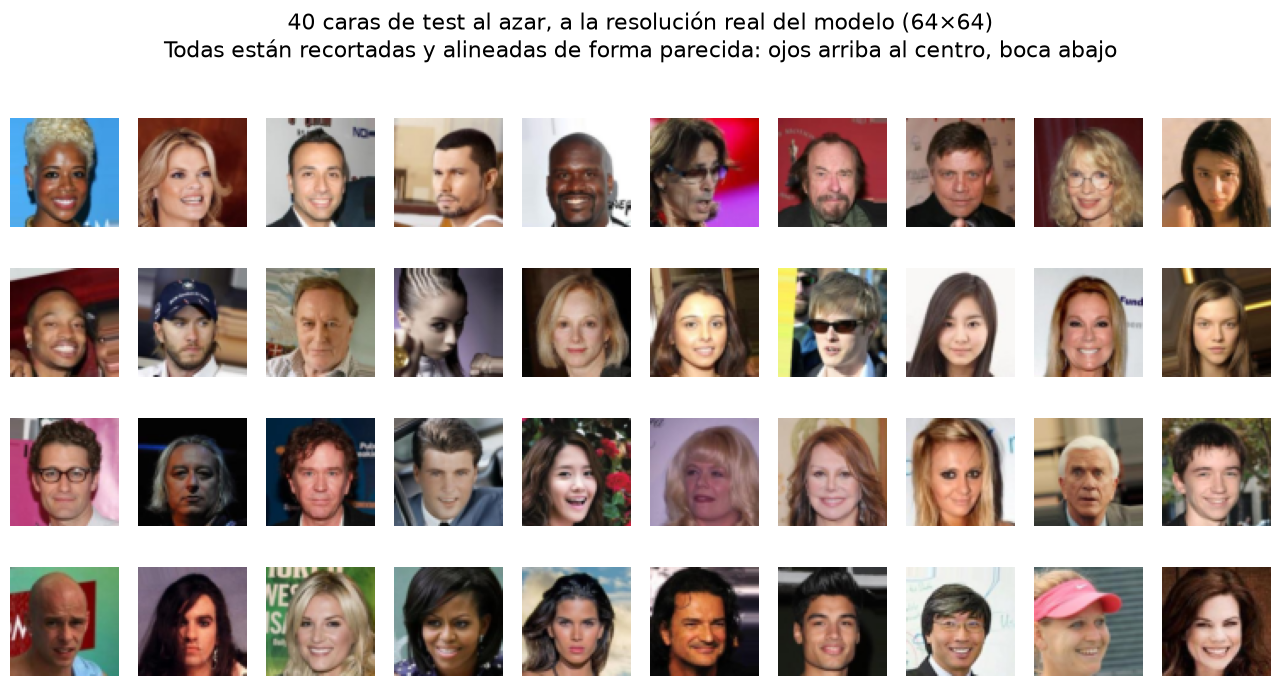

In [5]:
rng = np.random.default_rng(0)
idx = rng.choice(N, 40, replace=False)
fig, axes = plt.subplots(4, 10, figsize=FIG)
for ax, i in zip(axes.ravel(), idx):
    ax.imshow(X8[i]); ax.axis("off")
fig.suptitle("40 caras de test al azar, a la resolución real del modelo (64×64)\nTodas están recortadas y alineadas de forma parecida: ojos arriba al centro, boca abajo", fontsize=16)
plt.tight_layout(); save_fig(fig, "03_random_faces", OUTPUT_DIR, tag="celeba", project_root=project_root); plt.show()

## 4. Imágenes promedio: la "cara media" y la variabilidad

Promedio píxel a píxel de las 19 962 imágenes de test. Si las caras están bien alineadas, el promedio es **una cara nítida** (ojos y boca reconocibles); si no lo estuvieran, saldría una mancha. La imagen de la derecha en la primera fila muestra la **desviación típica por píxel**: dónde varía más la imagen (pelo, fondo, hombros) y dónde casi no (el centro de la cara).

Debajo, la cara media por grupos (hombres/mujeres, Attractive/no, gafas, sonrisa, joven). Las diferencias entre grupos muestran qué rasgos separan cada etiqueta *en promedio*.

guardado: experimentation/experiments/02112026_celeba_dataset/04_mean_faces_celeba.png


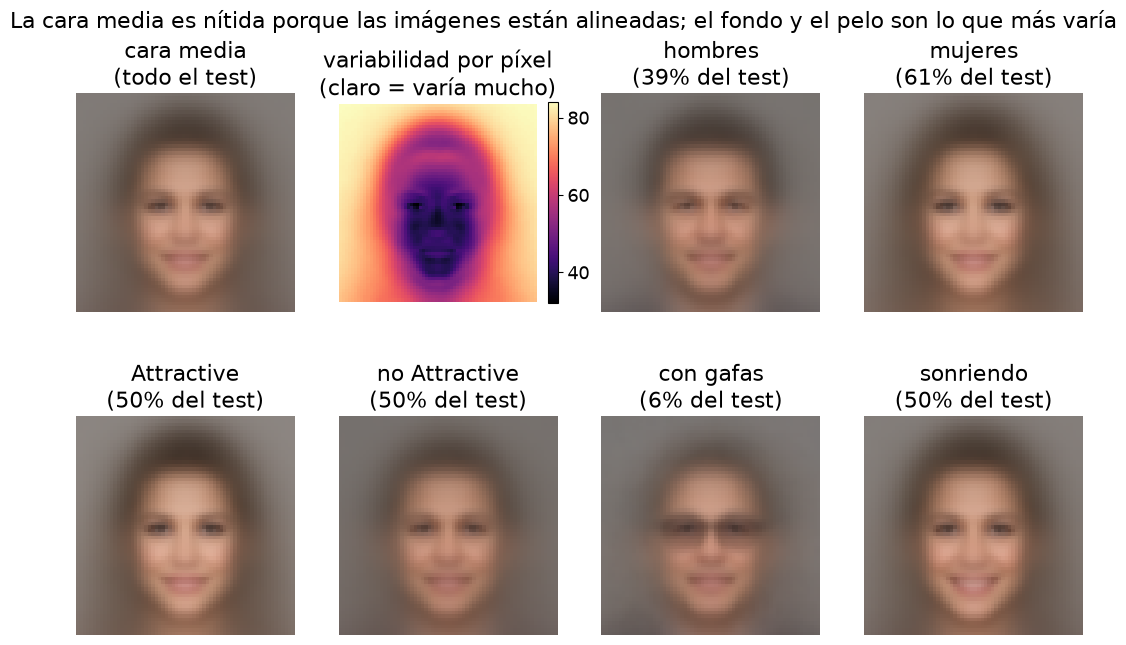

In [6]:
def media(mask): return X8[mask].mean(0).astype(np.uint8)
col = lambda n: ATTR_T[:, ATTR_T_NAMES.index(n)] == 1
gris = X8.mean(-1).astype(np.float32)
std_img = gris.std(0)

fig = plt.figure(figsize=FIG)
gs = fig.add_gridspec(2, 4, hspace=0.35)
ax = fig.add_subplot(gs[0, 0]); ax.imshow(X8.mean(0).astype(np.uint8)); ax.set_title("cara media\n(todo el test)"); ax.axis("off")
ax = fig.add_subplot(gs[0, 1]); im = ax.imshow(std_img, cmap="magma"); ax.set_title("variabilidad por píxel\n(claro = varía mucho)"); ax.axis("off")
fig.colorbar(im, ax=ax, fraction=0.046)
pares = [("Male", "hombres"), ("Male", "mujeres"), ("Attractive", "Attractive"), ("Attractive", "no Attractive"),
         ("Eyeglasses", "con gafas"), ("Smiling", "sonriendo"), ("Young", "jóvenes"), ("Young", "no jóvenes")]
pos = [(0, 2), (0, 3), (1, 0), (1, 1), (1, 2), (1, 3)]
sel = [("Male", True, "hombres"), ("Male", False, "mujeres"), ("Attractive", True, "Attractive"), ("Attractive", False, "no Attractive"),
       ("Eyeglasses", True, "con gafas"), ("Smiling", True, "sonriendo")]
for (r, c), (n, v, t) in zip(pos, sel):
    ax = fig.add_subplot(gs[r, c]); m = col(n) if v else ~col(n)
    ax.imshow(media(m)); ax.set_title(f"{t}\n({m.mean():.0%} del test)"); ax.axis("off")
fig.suptitle("La cara media es nítida porque las imágenes están alineadas; el fondo y el pelo son lo que más varía", fontsize=16)
save_fig(fig, "04_mean_faces", OUTPUT_DIR, tag="celeba", project_root=project_root); plt.show()

## 5. Alineación: dónde caen los landmarks

**Este es el dato clave para interpretar los mapas de atención.** CelebA está alineada: los ojos, la nariz y la boca caen casi siempre en los mismos píxeles. La figura superpone los 5 landmarks de las 19 962 imágenes. Una nube pequeña = alineación estricta. Si la dispersión es menor que un parche (4 px), **mirar un parche fijo equivale a mirar siempre la misma parte de la cara**, aunque la cabeza no "detecte" nada. Por eso un parche fijo no demuestra un detector.

guardado: experimentation/experiments/02112026_celeba_dataset/05_landmark_alignment_celeba.png


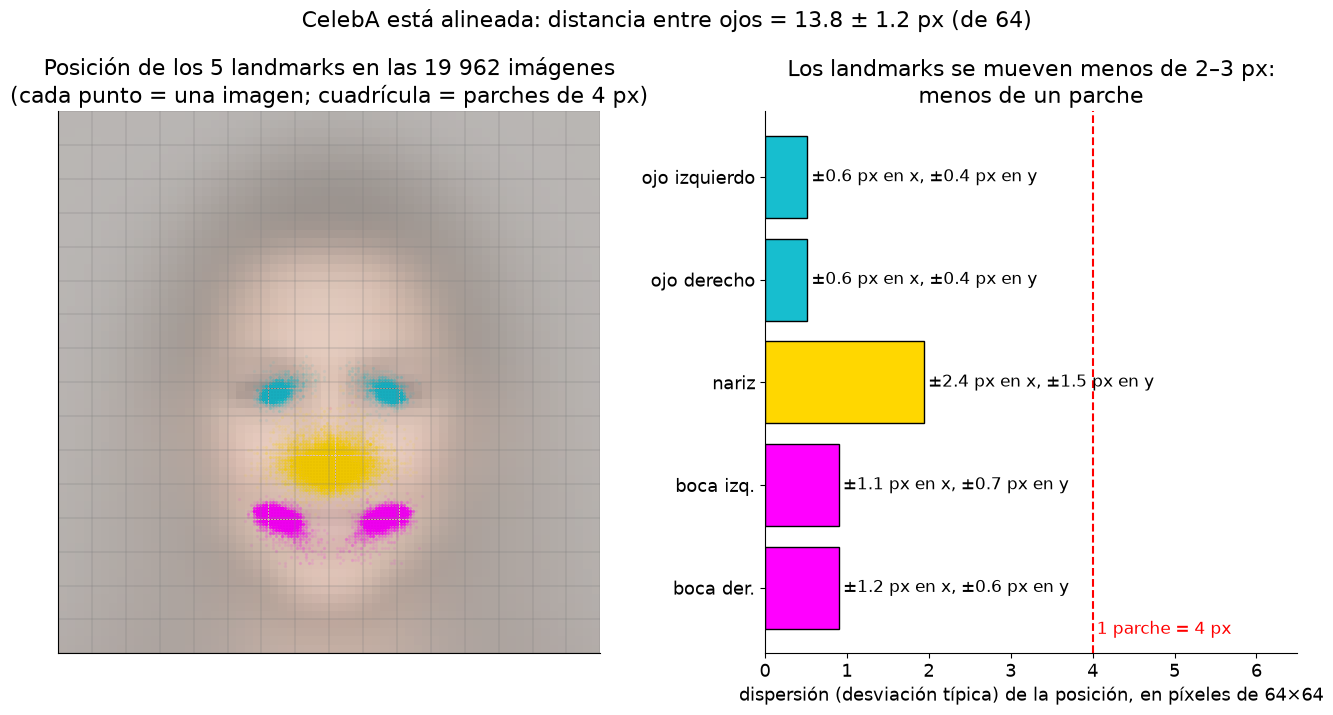

               σx (px)  σy (px)
ojo izquierdo     0.62     0.41
ojo derecho       0.61     0.42
nariz             2.37     1.51
boca izq.         1.14     0.66
boca der.         1.17     0.64


In [7]:
nombres = ["ojo izquierdo", "ojo derecho", "nariz", "boca izq.", "boca der."]
colores = ["tab:cyan", "tab:cyan", "gold", "magenta", "magenta"]
fig, (ax, ax2) = plt.subplots(1, 2, figsize=FIG, gridspec_kw={"width_ratios": [1.1, 1]})
ax.imshow(X8.mean(0).astype(np.uint8), alpha=0.55)
for k in range(5):
    ax.scatter(LM[:, k, 0], LM[:, k, 1], s=2, alpha=0.06, color=colores[k])
for g in range(0, IMG + 1, PATCH):
    ax.axhline(g - 0.5, color="gray", lw=0.3); ax.axvline(g - 0.5, color="gray", lw=0.3)
ax.set_xlim(-0.5, IMG - 0.5); ax.set_ylim(IMG - 0.5, -0.5); ax.set_xticks([]); ax.set_yticks([])
ax.set_title("Posición de los 5 landmarks en las 19 962 imágenes\n(cada punto = una imagen; cuadrícula = parches de 4 px)")
sd = np.array([[LM[:, k, 0].std(), LM[:, k, 1].std()] for k in range(5)])
ax2.barh(range(5), sd.mean(1), color=colores, edgecolor="k")
for k in range(5):
    ax2.text(sd[k].mean() + 0.05, k, f"±{sd[k, 0]:.1f} px en x, ±{sd[k, 1]:.1f} px en y", va="center", fontsize=12)
ax2.axvline(PATCH, color="red", ls="--"); ax2.text(PATCH + 0.05, 4.45, "1 parche = 4 px", color="red", fontsize=12)
ax2.set_yticks(range(5)); ax2.set_yticklabels(nombres); ax2.invert_yaxis(); ax2.set_xlim(0, 6.5)
ax2.set_xlabel("dispersión (desviación típica) de la posición, en píxeles de 64×64")
ax2.set_title("Los landmarks se mueven menos de 2–3 px:\nmenos de un parche")
iod = np.linalg.norm(LM[:, 0] - LM[:, 1], axis=1)
fig.suptitle(f"CelebA está alineada: distancia entre ojos = {iod.mean():.1f} ± {iod.std():.1f} px (de 64)", fontsize=16)
plt.tight_layout(); save_fig(fig, "05_landmark_alignment", OUTPUT_DIR, tag="celeba", project_root=project_root); plt.show()
print(pd.DataFrame({"σx (px)": sd[:, 0], "σy (px)": sd[:, 1]}, index=nombres).round(2))

## 6. Los 40 atributos: qué tan frecuentes son

Porcentaje de imágenes con cada atributo (sobre las **202 599** imágenes). Los colores agrupan los atributos por tipo. Dos lecturas importantes:
- **Muchos atributos están muy desbalanceados** (`Bald`, `Mustache`, `Wearing_Necktie` con pocos %). Un modelo que siempre dijera "no" ya acertaría muy a menudo: la exactitud media de 0.88 hay que compararla con ese piso (sección 9).
- Hay atributos que cuentan como **muy "objetivos"** (`Eyeglasses`, `Wearing_Hat`) y otros **subjetivos** (`Attractive`, `Young`, `Big_Nose`, `Chubby`).

guardado: experimentation/experiments/02112026_celeba_dataset/06_attribute_prevalence_celeba.png


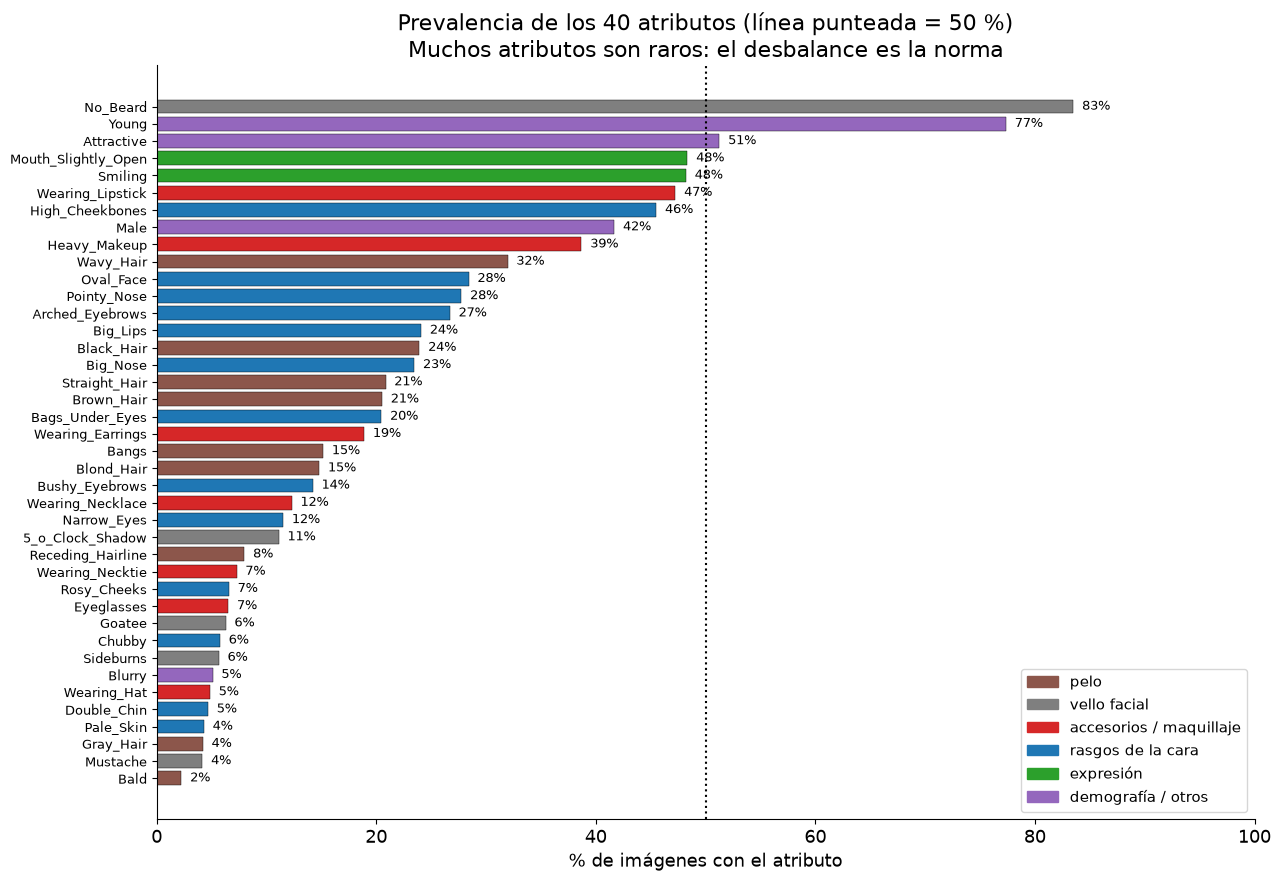

In [8]:
CATEG = {
    "pelo": ["Bald", "Bangs", "Black_Hair", "Blond_Hair", "Brown_Hair", "Gray_Hair", "Receding_Hairline", "Straight_Hair", "Wavy_Hair"],
    "vello facial": ["5_o_Clock_Shadow", "Goatee", "Mustache", "Sideburns", "No_Beard"],
    "accesorios / maquillaje": ["Eyeglasses", "Wearing_Earrings", "Wearing_Hat", "Wearing_Lipstick", "Wearing_Necklace", "Wearing_Necktie", "Heavy_Makeup"],
    "rasgos de la cara": ["Arched_Eyebrows", "Bags_Under_Eyes", "Big_Lips", "Big_Nose", "Bushy_Eyebrows", "Double_Chin", "High_Cheekbones",
                          "Narrow_Eyes", "Oval_Face", "Pointy_Nose", "Rosy_Cheeks", "Chubby", "Pale_Skin"],
    "expresión": ["Mouth_Slightly_Open", "Smiling"],
    "demografía / otros": ["Male", "Young", "Attractive", "Blurry"],
}
COLC = dict(zip(CATEG, ["tab:brown", "tab:gray", "tab:red", "tab:blue", "tab:green", "tab:purple"]))
cat_de = {a: c for c, v in CATEG.items() for a in v}
assert set(cat_de) == set(ATTR_NAMES), set(ATTR_NAMES) ^ set(cat_de)
prev = A.mean().sort_values()
fig, ax = plt.subplots(figsize=(13, 9))
ax.barh(prev.index, prev.values * 100, color=[COLC[cat_de[a]] for a in prev.index], edgecolor="k", lw=0.3)
for y_, v in enumerate(prev.values):
    ax.text(v * 100 + 0.8, y_, f"{v:.0%}", va="center", fontsize=9)
ax.axvline(50, color="k", ls=":")
ax.set_xlabel("% de imágenes con el atributo"); ax.set_xlim(0, 100); ax.tick_params(axis="y", labelsize=9)
ax.legend([Rectangle((0, 0), 1, 1, color=c) for c in COLC.values()], list(COLC), loc="lower right", fontsize=11)
ax.set_title("Prevalencia de los 40 atributos (línea punteada = 50 %)\nMuchos atributos son raros: el desbalance es la norma")
plt.tight_layout(); save_fig(fig, "06_attribute_prevalence", OUTPUT_DIR, tag="celeba", project_root=project_root); plt.show()

## 7. Género y `Attractive`: qué hay detrás de una etiqueta

CelebA trae `Male` como atributo binario (es la etiqueta de los anotadores, no una medida de nada más). Tres figuras:
1. proporción de hombres/mujeres, en cada partición (¿la partición está balanceada?);
2. **tasa de `Attractive` por género y edad**: muestra de dónde sale la correlación de `Attractive` con `Male` y `Young` que vimos en el notebook de `Attractive`;
3. los atributos que **más cambian entre mujeres y hombres**: son casi "proxies" de género.

guardado: experimentation/experiments/02112026_celeba_dataset/07_gender_attractive_celeba.png


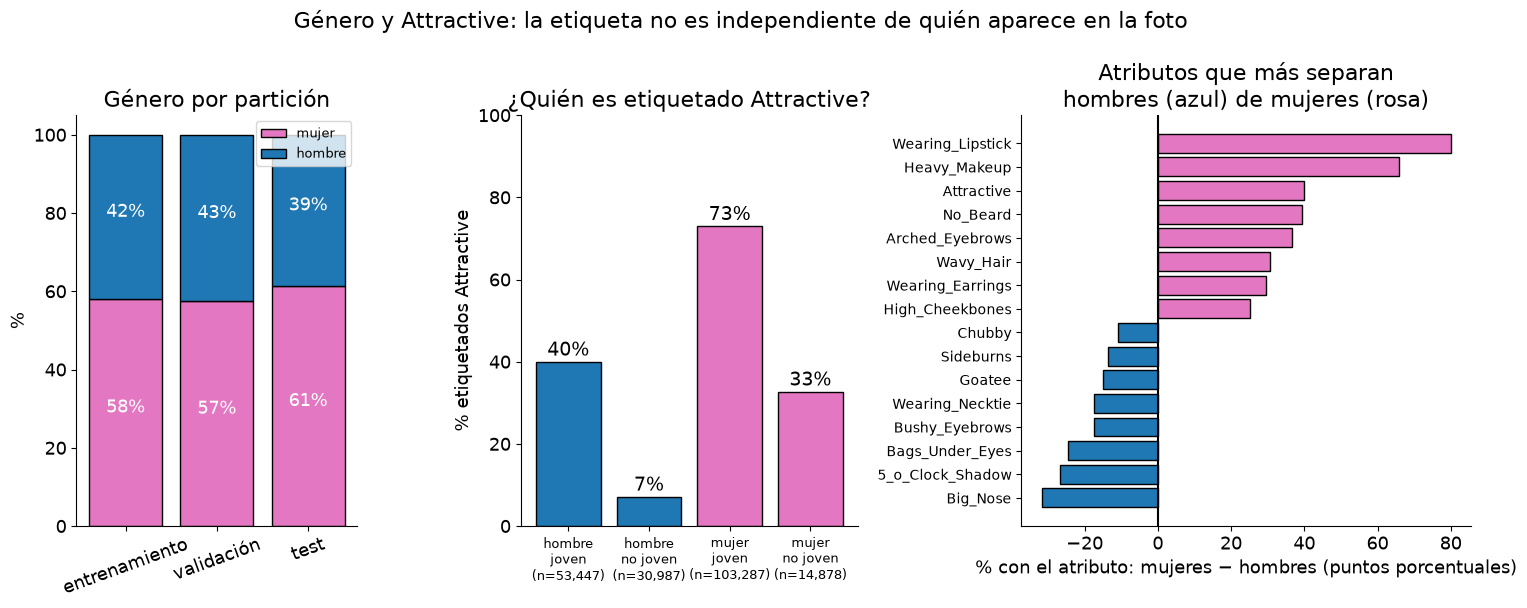

        g         e   mean    size
0  hombre     joven  0.400   53447
1  hombre  no joven  0.071   30987
2   mujer     joven  0.730  103287
3   mujer  no joven  0.327   14878


In [9]:
male = A["Male"] == 1
fig, ax = plt.subplots(1, 3, figsize=(15, 6.2), gridspec_kw={"width_ratios": [1, 1.2, 1.6]})
# (1) género por partición
g = pd.crosstab(split, male, normalize="index").reindex(["entrenamiento", "validación", "test"])
ax[0].bar(g.index, g[False] * 100, color="tab:pink", edgecolor="k", label="mujer")
ax[0].bar(g.index, g[True] * 100, bottom=g[False] * 100, color="tab:blue", edgecolor="k", label="hombre")
for k, (a_, b_) in enumerate(zip(g[False], g[True])):
    ax[0].text(k, a_ * 100 / 2, f"{a_:.0%}", ha="center", color="w", fontsize=13); ax[0].text(k, a_ * 100 + b_ * 100 / 2, f"{b_:.0%}", ha="center", color="w", fontsize=13)
ax[0].set_ylabel("%"); ax[0].set_title("Género por partición"); ax[0].tick_params(axis="x", rotation=20); ax[0].legend(loc="upper right", fontsize=9)
# (2) Attractive por género × edad
grupo = pd.DataFrame({"g": np.where(male, "hombre", "mujer"), "e": np.where(A["Young"] == 1, "joven", "no joven"), "att": A["Attractive"]})
t = grupo.groupby(["g", "e"])["att"].agg(["mean", "size"]).reset_index()
etiq = [f"{r.g}\n{r.e}\n(n={r['size']:,})" for _, r in t.iterrows()]
bars = ax[1].bar(range(len(t)), t["mean"] * 100, color=["tab:pink" if x == "mujer" else "tab:blue" for x in t["g"]], edgecolor="k")
for k, v in enumerate(t["mean"]): ax[1].text(k, v * 100 + 1.5, f"{v:.0%}", ha="center", fontsize=14)
ax[1].set_xticks(range(len(t))); ax[1].set_xticklabels(etiq, fontsize=9); ax[1].set_ylim(0, 100)
ax[1].set_ylabel("% etiquetados Attractive"); ax[1].set_title("¿Quién es etiquetado Attractive?")
# (3) atributos que más cambian entre mujeres y hombres
dif = (A[~male].mean() - A[male].mean()).drop("Male").sort_values()
sel = pd.concat([dif.head(8), dif.tail(8)])
ax[2].barh(sel.index, sel.values * 100, color=["tab:blue" if v < 0 else "tab:pink" for v in sel.values], edgecolor="k")
ax[2].axvline(0, color="k"); ax[2].set_xlabel("% con el atributo: mujeres − hombres (puntos porcentuales)"); ax[2].tick_params(axis="y", labelsize=10)
ax[2].set_title("Atributos que más separan\nhombres (azul) de mujeres (rosa)")
fig.suptitle("Género y Attractive: la etiqueta no es independiente de quién aparece en la foto", fontsize=16)
plt.tight_layout(); save_fig(fig, "07_gender_attractive", OUTPUT_DIR, tag="celeba", project_root=project_root); plt.show()
print(t.round(3))

## 8. Qué atributos van juntos (correlaciones)

Matriz de correlación entre los 40 atributos (ordenados por similitud; rojo = aparecen juntos, azul = se excluyen). Los bloques rojos son grupos de atributos **que casi no se pueden separar** (p. ej. maquillaje, labial, ser mujer, `Attractive`). Esto es lo que complica probar que una cabeza "capta" un atributo concreto: se confunde con sus acompañantes. Abajo, los 10 atributos más ligados a `Attractive`.

guardado: experimentation/experiments/02112026_celeba_dataset/08_attribute_correlations_celeba.png


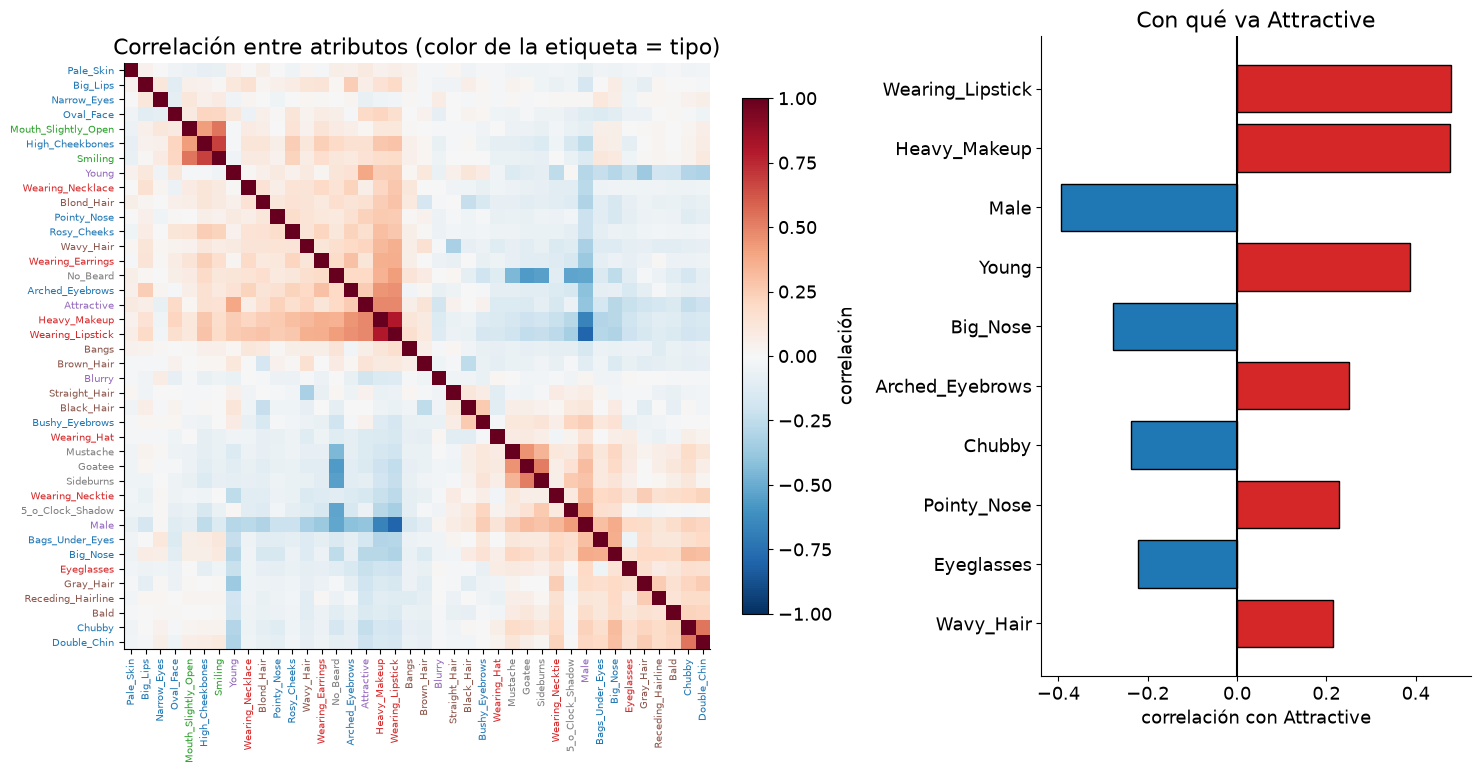

In [10]:
from scipy.cluster.hierarchy import leaves_list, linkage
C_ = pd.DataFrame(np.corrcoef(A.values.T.astype(float)), index=ATTR_NAMES, columns=ATTR_NAMES).fillna(0)
orden = [ATTR_NAMES[i] for i in leaves_list(linkage(1 - C_.values[np.triu_indices(40, 1)], method="average"))]
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(15, 8), gridspec_kw={"width_ratios": [1.5, 1]})
im = ax.imshow(C_.loc[orden, orden].values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(40)); ax.set_xticklabels(orden, rotation=90, fontsize=7.5); ax.set_yticks(range(40)); ax.set_yticklabels(orden, fontsize=7.5)
for lab in ax.get_xticklabels() + ax.get_yticklabels():
    lab.set_color(COLC[cat_de[lab.get_text()]])
fig.colorbar(im, ax=ax, fraction=0.04, label="correlación")
ax.set_title("Correlación entre atributos (color de la etiqueta = tipo)")
co = C_["Attractive"].drop("Attractive"); co = co.reindex(co.abs().sort_values(ascending=False).index).head(10)[::-1]
ax2.barh(co.index, co.values, color=["tab:red" if v > 0 else "tab:blue" for v in co.values], edgecolor="k")
ax2.axvline(0, color="k"); ax2.set_xlabel("correlación con Attractive"); ax2.set_title("Con qué va Attractive")
plt.tight_layout(); save_fig(fig, "08_attribute_correlations", OUTPUT_DIR, tag="celeba", project_root=project_root); plt.show()

## 9. ¿Qué tan buena es una exactitud de 0.88? El piso del "siempre la clase mayoritaria"

Los modelos de CelebA reportan una exactitud media de ~0.88 sobre los 40 atributos. Como los atributos están desbalanceados (sección 6), conviene compararla con un clasificador **tonto** que siempre responde la clase más frecuente de cada atributo. Se calcula sobre el test.

guardado: experimentation/experiments/02112026_celeba_dataset/09_accuracy_vs_majority_baseline_celeba.png


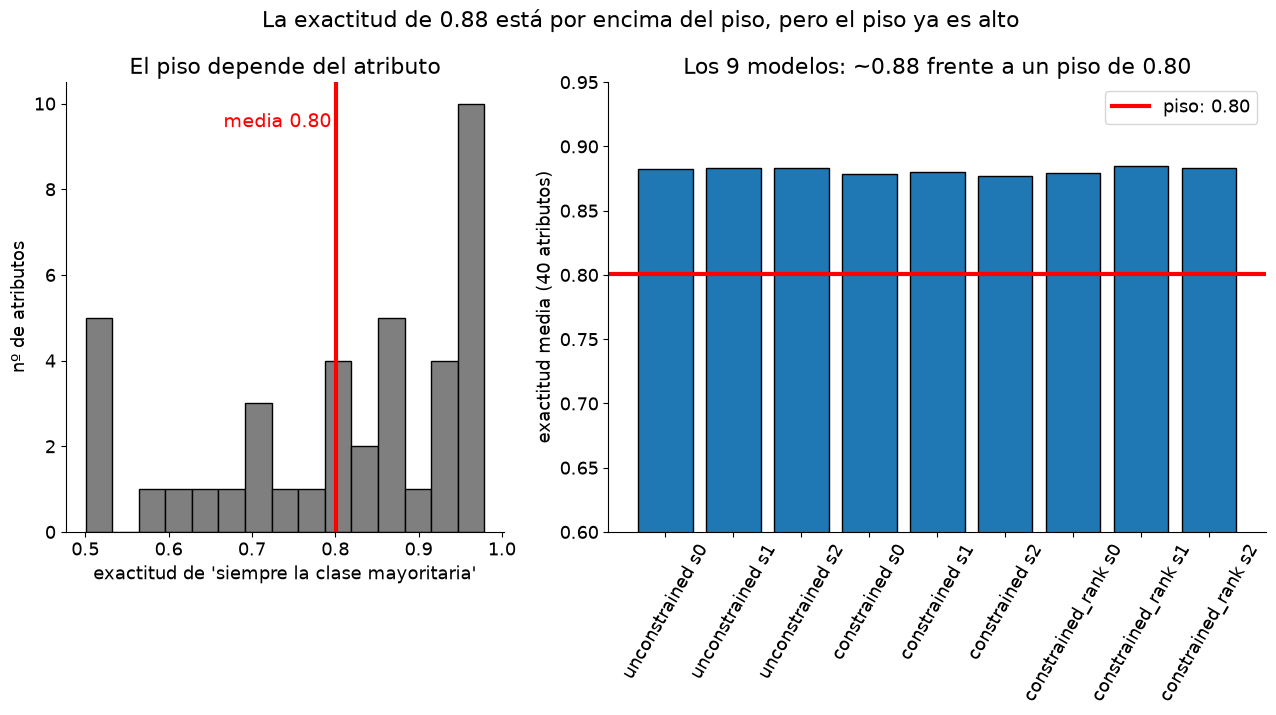

piso medio (mayoritaria): 0.800 | modelos: 0.881


In [11]:
import json
ptest = pd.DataFrame(ATTR_T, columns=ATTR_T_NAMES).mean()
piso = np.maximum(ptest, 1 - ptest)                        # exactitud de "siempre la clase mayoritaria", por atributo
filas = []
for v in ["unconstrained", "constrained", "constrained_rank"]:
    for s in range(3):
        f = project_root / "experimentation" / "experiments" / f"vit-5-{v}-s{s}-CelebA" / "metrics.json"
        if f.exists(): filas.append({"modelo": f"{v} s{s}", "exactitud": json.loads(f.read_text())["accuracy"]})
M_ = pd.DataFrame(filas)
fig, (ax, ax2) = plt.subplots(1, 2, figsize=FIG, gridspec_kw={"width_ratios": [1, 1.5]})
ax.hist(piso, bins=15, color="tab:gray", edgecolor="k"); ax.axvline(piso.mean(), color="red", lw=3)
ax.text(piso.mean() - 0.005, ax.get_ylim()[1] * 0.9, f"media {piso.mean():.2f}", color="red", ha="right", fontsize=14)
ax.set_xlabel("exactitud de 'siempre la clase mayoritaria'"); ax.set_ylabel("nº de atributos"); ax.set_title("El piso depende del atributo")
if len(M_):
    ax2.bar(M_["modelo"], M_["exactitud"], color="tab:blue", edgecolor="k"); ax2.axhline(piso.mean(), color="red", lw=3, label=f"piso: {piso.mean():.2f}")
    ax2.set_ylim(0.6, 0.95); ax2.tick_params(axis="x", rotation=60); ax2.legend(); ax2.set_ylabel("exactitud media (40 atributos)")
    ax2.set_title(f"Los 9 modelos: ~{M_['exactitud'].mean():.2f} frente a un piso de {piso.mean():.2f}")
fig.suptitle("La exactitud de 0.88 está por encima del piso, pero el piso ya es alto", fontsize=16)
plt.tight_layout(); save_fig(fig, "09_accuracy_vs_majority_baseline", OUTPUT_DIR, tag="celeba", project_root=project_root); plt.show()
print(f"piso medio (mayoritaria): {piso.mean():.3f} | modelos: {M_['exactitud'].mean():.3f}")

## 10. Resumen en una diapositiva

/tmp/ipykernel_191/2076425744.py:1: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  n_pos = A.sum(1)


guardado: experimentation/experiments/02112026_celeba_dataset/10_summary_slide_celeba.png


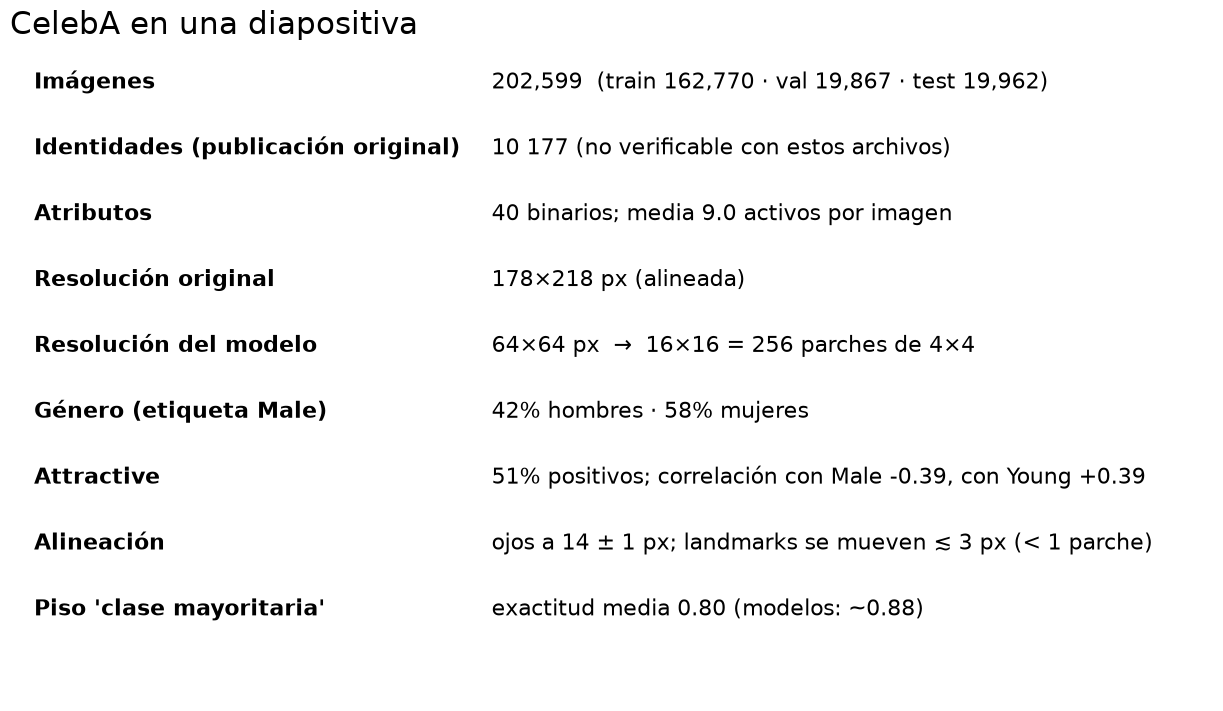

In [12]:
n_pos = A.sum(1)
datos = [("Imágenes", f"{len(A):,}  (train {cuenta['entrenamiento']:,} · val {cuenta['validación']:,} · test {cuenta['test']:,})"),
         ("Identidades (publicación original)", "10 177 (no verificable con estos archivos)"),
         ("Atributos", f"40 binarios; media {n_pos.mean():.1f} activos por imagen"),
         ("Resolución original", f"{RAW_W}×{RAW_H} px (alineada)"),
         ("Resolución del modelo", f"{IMG}×{IMG} px  →  {GRID}×{GRID} = {GRID * GRID} parches de {PATCH}×{PATCH}"),
         ("Género (etiqueta Male)", f"{male.mean():.0%} hombres · {1 - male.mean():.0%} mujeres"),
         ("Attractive", f"{A['Attractive'].mean():.0%} positivos; correlación con Male {C_.loc['Attractive', 'Male']:+.2f}, con Young {C_.loc['Attractive', 'Young']:+.2f}"),
         ("Alineación", f"ojos a {iod.mean():.0f} ± {iod.std():.0f} px; landmarks se mueven ≲ 3 px (< 1 parche)"),
         ("Piso 'clase mayoritaria'", f"exactitud media {piso.mean():.2f} (modelos: ~{M_['exactitud'].mean():.2f})")]
fig, ax = plt.subplots(figsize=FIG); ax.axis("off")
for k, (a_, b_) in enumerate(datos):
    y_ = 0.93 - k * 0.1
    ax.text(0.02, y_, a_, fontsize=16, fontweight="bold", transform=ax.transAxes); ax.text(0.40, y_, b_, fontsize=16, transform=ax.transAxes)
ax.set_title("CelebA en una diapositiva", fontsize=22, loc="left")
plt.tight_layout(); save_fig(fig, "10_summary_slide", OUTPUT_DIR, tag="celeba", project_root=project_root); plt.show()

## 11. Limitaciones del dataset (para la discusión de la tesis)

- **Son celebridades**, fotografiadas casi siempre con buena iluminación y pose frontal: no representa caras "del mundo real". La alineación estricta (sección 5) facilita lo que medimos y **no se mantendría** con fotos sin alinear.
- **Sesgo demográfico:** la mayoría de las personas son de aspecto occidental y jóvenes; la etiqueta de género es binaria y la asignan anotadores.
- **Etiquetas subjetivas y con ruido:** `Attractive`, `Young`, `Big_Nose`, `Chubby`, `Pale_Skin`, `Blurry` dependen del criterio del anotador. `Attractive` además va ligado a género, edad y maquillaje (secciones 7 y 8).
- **Desbalance fuerte** en muchos atributos (sección 6): la exactitud sola engaña (sección 9).
- **Resolución baja en los modelos (64×64 con parches de 4×4):** los ojos son 1–2 parches; los resultados de "región" tienen esa resolución como límite.
- **Los atributos son globales:** no dicen *dónde* está el rasgo (salvo los 5 landmarks). Las "cajas" del dataset original están en coordenadas de la foto sin alinear y no se pueden usar con estas imágenes.